# Rapport final — Optimisation de tournées de livraison (CVRP)

**Projet CesiCDP — Réponse à l'appel à manifestation d'intérêt de l'ADEME**

Ce rapport rassemble la modélisation formelle, l'analyse de complexité, le PLNE, ses méthodes de résolution, l'algorithme génétique et l'étude expérimentale complète. Le périmètre implémenté est le **CVRP niveau B** : dépôt unique, flotte homogène, capacité identique, demandes clients et coûts d'arcs fixes.

**Résumé.** Le PLNE avec Branch and Bound fournit des solutions optimales prouvées sur les petites instances. L'algorithme génétique cherche rapidement des solutions faisables sur des instances plus grandes, sans garantie d'optimalité. Les deux solveurs reçoivent une instance chargée dans ce notebook via `common.load_instance`.

---

**Plan du rapport**
1. Contexte et périmètre
2. Hypothèses et données du modèle
3. Définition formelle du problème
4. Complexité
5. Modèle mathématique en PLNE
6. Limites de la modélisation et prolongements
7. Du PLNE à la métaheuristique : pourquoi deux méthodes ?
8. Choix des instances expérimentales
9. Résolution exacte : PLNE et Branch and Bound
10. Métaheuristique retenue : algorithme génétique
11. Étude expérimentale complète
12. Conclusion, limites et axes d'amélioration
13. Références bibliographiques

## 1. Contexte et périmètre

CesiCDP souhaite optimiser des tournées de livraison afin de réduire les déplacements et leur impact environnemental. Une flotte de camions part d'un dépôt, dessert des clients ayant chacun une demande, puis revient au dépôt. Le coût d'un trajet entre deux lieux représente ici une distance ou une durée de trajet connue.

L'énoncé évoque un trafic qui varie selon les tranches horaires et une version avancée avec fenêtres de livraison. Le projet retient d'abord le **niveau B attendu** : le CVRP à capacité identique, demandes clients, dépôt unique et coût de trajet fixe. Le code ne modélise donc pas encore les fenêtres, l'attente ni le trafic dépendant de l'heure.

L'objectif est de minimiser la somme des coûts des arcs parcourus. Chaque client doit être visité exactement une fois, la charge de chaque camion ne doit pas dépasser sa capacité et chaque tournée doit partir du dépôt et y revenir.

## 2. Hypothèses et données du modèle

On considère un graphe complet orienté. Le coût direct entre deux sommets peut être la longueur ou la durée du plus court chemin routier pré-calculé. Les coûts sont non négatifs et fixes pendant une tournée. Chaque véhicule utilisé dessert au moins un client. La flotte contient au plus `m` véhicules : certains peuvent rester inutilisés.

### Ensembles et paramètres

- $C=\{1,\ldots,n\}$ : clients ; $0$ : dépôt ; $V=C\cup\{0\}$.
- $K=\{1,\ldots,m\}$ : véhicules disponibles.
- $q_i>0$ : demande du client $i\in C$.
- $Q>0$ : capacité identique de chaque véhicule.
- $c_{ij}\geq0$ : coût du déplacement de $i$ vers $j$, pour $i,j\in V$, $i\ne j$.
- Condition nécessaire de faisabilité globale : $\sum_{i\in C}q_i\leq mQ$.

Cette condition globale n'est pas suffisante à elle seule : chaque demande doit également tenir dans la capacité d'un camion. Si le réseau initial est incomplet, $c_{ij}$ peut être calculé comme le coût du plus court chemin entre deux lieux. L'unité (km ou minutes), la convention de distance et le scénario de circulation doivent être documentés. Dans les expériences CVRPLIB, les distances EUC_2D suivent la convention d'arrondi de la bibliothèque.

## 3. Définition formelle du problème

**Entrée :** les clients avec leurs demandes, un dépôt, au plus $m$ véhicules de capacité $Q$ et les coûts $c_{ij}$.

**Solution réalisable :** au plus $m$ circuits partant du dépôt et y revenant, couvrant chaque client exactement une fois, avec une demande totale par circuit au plus égale à $Q$.

**Objectif :** minimiser le coût total des arcs utilisés sur toutes les tournées.

La version décisionnelle ajoute un seuil $B$ à l'entrée et demande s'il existe une solution réalisable de coût total inférieur ou égal à $B$.

## 4. Complexité

### Appartenance à NP

Un certificat est constitué des tournées. En temps polynomial, on peut vérifier que le nombre de tournées ne dépasse pas $m$, que chaque tournée part du dépôt et y revient, que chaque client apparaît exactement une fois, que chaque charge est au plus $Q$, et que le coût total ne dépasse pas $B$. La version décisionnelle du CVRP appartient donc à NP.

### NP-difficulté par réduction du TSP

On part d'une instance décisionnelle du TSP avec villes $v_0,\ldots,v_n$, coûts $c_{ij}$ et seuil $B$. On construit en temps polynomial une instance du CVRP en prenant $v_0$ comme dépôt, les autres villes comme clients, le même coût $c_{ij}$, une demande $q_i=1$ pour chaque client, un seul véhicule ($m=1$) et une capacité $Q=n$.

- Une tournée TSP de coût au plus $B$ visite chaque ville une fois et revient à $v_0$. Elle définit donc une tournée CVRP faisable de même coût.
- Toute solution CVRP de cette instance n'utilise qu'un véhicule et doit visiter chaque client exactement une fois. Elle définit donc une tournée TSP de même coût.

Les deux instances ont ainsi la même réponse. Comme le TSP décisionnel est NP-complet, le CVRP décisionnel est NP-difficile ; avec son appartenance à NP, il est NP-complet. Le problème d'optimisation CVRP est NP-difficile.

## 5. Modèle mathématique en PLNE

La formulation suivante est indexée par véhicule. Elle exprime explicitement l'affectation des clients et l'utilisation des camions.

### 5.1 Ensembles et variables

On note $A=\{(i,j)\in V^2:i\ne j\}$ l'ensemble des arcs possibles.

- $x_{ijk}\in\{0,1\}$ : le véhicule $k$ emprunte directement l'arc $i\to j$.
- $y_{ik}\in\{0,1\}$ : le client $i$ est affecté au véhicule $k$.
- $z_k\in\{0,1\}$ : le véhicule $k$ est utilisé.
- $u_{ik}\geq0$ : charge cumulée livrée par $k$ jusqu'à sa visite de $i$.

Les variables $x$ décrivent les déplacements, $y$ l'affectation, $z$ l'utilisation des camions et $u$ la progression de la charge. Les variables auxiliaires peuvent ne pas apparaître dans l'objectif.

### 5.2 Fonction objectif

$$\min Z=\sum_{k\in K}\sum_{(i,j)\in A}c_{ij}x_{ijk}$$

Le coût $c_{ij}$ représente une distance ou une durée statique. La somme additionne le coût de chaque arc parcouru par chaque véhicule.

### 5.3 Contraintes

**A. Affectation unique**

$$\sum_{k\in K}y_{ik}=1 \qquad \forall i\in C$$

Chaque client est affecté à exactement un véhicule.

**B. Entrée et sortie de chaque client affecté**

$$\sum_{j\in V\setminus\{i\}}x_{ijk}=y_{ik},\qquad
\sum_{j\in V\setminus\{i\}}x_{jik}=y_{ik}
\qquad \forall i\in C, k\in K$$

Un client affecté a exactement un arc entrant et un arc sortant pour ce véhicule ; les deux sommes sont nulles s'il ne lui est pas affecté.

**C. Départ et retour au dépôt**

$$\sum_{j\in C}x_{0jk}=z_k,\qquad
\sum_{i\in C}x_{i0k}=z_k
\qquad \forall k\in K$$

Chaque véhicule utilisé part une fois du dépôt et y revient une fois. Un véhicule inutilisé n'emprunte aucun arc au départ ou au retour.

**D. Lien entre affectation et utilisation**

$$y_{ik}\leq z_k \qquad \forall i\in C, k\in K$$

**E. Capacité**

$$\sum_{i\in C}q_i y_{ik}\leq Qz_k \qquad \forall k\in K$$

La charge totale affectée à un camion reste dans sa capacité ; un camion inutilisé ne reçoit aucun client.

**F. Cohérence de charge et élimination des sous-tours**

$$q_i y_{ik}\leq u_{ik}\leq Qy_{ik}
\qquad \forall i\in C, k\in K$$

Pour deux clients distincts $i,j$ :

$$u_{jk}\geq u_{ik}+q_jy_{jk}-Q(1-x_{ijk})
\qquad \forall k\in K, i,j\in C, i\ne j$$

Si l'arc $i\to j$ est emprunté par le camion $k$, alors $x_{ijk}=1$ et les contraintes de flot impliquent $y_{jk}=1$. La charge augmente donc d'au moins $q_j$. Si l'arc n'est pas emprunté, le terme $-Q(1-x_{ijk})$ relâche la borne. Le facteur $y_{jk}$ est essentiel : sans lui, la charge d'un client affecté à un autre camion pourrait contraindre le camion $k$ et éliminer des solutions valides. Comme toutes les demandes sont strictement positives, un cycle de clients imposerait une augmentation stricte de charge à chaque arc puis un retour à la charge initiale ; aucun sous-tour client ne peut donc subsister.

**G. Domaines**

$$x_{ijk},y_{ik},z_k\in\{0,1\},\qquad u_{ik}\geq0$$

Les variables de charge peuvent être continues. La limite de flotte est respectée car l'ensemble $K$ contient exactement les $m$ véhicules disponibles.

### 5.4 Formulation implémentée

Le PLNE indexé par véhicule ci-dessus est construit par `build_vehicle_index_model`. Le solveur utilise aussi une formulation compacte à deux indices $(x_{ij},u_i)$, qui évite la symétrie entre véhicules. Cette formulation impose une entrée et une sortie par client, limite les départs du dépôt à la flotte, et utilise des contraintes MTZ renforcées pour la capacité et l'élimination des sous-tours. Les deux formulations représentent le même CVRP ; la formulation compacte est la valeur par défaut du Branch and Bound.

## 6. Limites de la modélisation et prolongements

Le modèle suppose des coûts d'arcs fixes. Il n'inclut ni fenêtres horaires, ni durée maximale de tournée, ni coûts d'émission séparés, ni trafic dépendant de l'heure. Pour le CVRPTW, il faudrait ajouter des variables d'heure d'arrivée, les bornes temporelles, l'interdiction de livrer hors fenêtre et la possibilité d'attendre. Pour le trafic variable, le temps de parcours d'un arc dépendrait de l'heure de départ ; il faudrait représenter cette dépendance dans les données et dans les contraintes.

Les données cartographiques demandent aussi une préparation : lieux des clients et du dépôt, demandes, matrice des coûts, unités et hypothèses de circulation. Les résultats actuels ne doivent donc pas être interprétés comme tenant compte des embouteillages horaires.

## 7. Du PLNE à la métaheuristique : pourquoi deux méthodes ?

Le CVRP décisionnel est NP-complet et son problème d'optimisation est NP-difficile. Cela ne signifie pas qu'il est impossible de résoudre des instances : un solveur exact peut trouver et prouver l'optimum de nombreux petits cas, et parfois de cas plus grands favorables. En revanche, les méthodes exactes ont une croissance combinatoire dans le pire cas. Pour les instances de plusieurs centaines ou milliers de clients, le Branch and Bound peut devoir explorer trop de sous-problèmes pour terminer dans un temps raisonnable ; aucune durée pratique n'est garantie.

Nous conservons donc les deux approches avec des objectifs différents : le **PLNE** sert à obtenir une preuve d'optimalité, des bornes et une référence sur de petites instances ; l'**algorithme génétique** cherche rapidement de bonnes solutions faisables sur des instances plus grandes, sans certifier qu'elles sont optimales. Le passage au génétique répond ainsi à la limite pratique de calcul de la méthode exacte, sans prétendre que la NP-complétude rend toute résolution impossible.

## 8. Choix des instances expérimentales

Pour répondre à l'exigence du cahier des charges de tester l'algorithme sur **au moins 20 instances réelles**, nous retenons un ensemble de **23 instances issues du benchmark officiel VRPLIB** (séries A, B, E et P de la littérature) présentes dans le dossier `data/` :

- **Série E** (Christofides & Eilon, 1969) : 4 instances (12 à 50 clients) ;
- **Série P** (Augerat et al., 1995) : 5 instances (15 à 49 clients) ;
- **Série B** (Augerat et al., 1995) : 5 instances (30 à 49 clients) ;
- **Série A** (Augerat et al., 1995) : 9 instances (31 à 79 clients).

Toutes ces instances disposent d'une **solution optimale documentée** (fichier `.sol`). Cela élimine tout biais d'instances artificielles infaisables et permet de mesurer rigoureusement le **gap d'optimalité exact** pour 100 % du jeu d'essai.

In [1]:
import time
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

from common import (
    load_instance, check_solution, solution_cost, route_cost,
    route_load, gap, plot_solution, sub_instance
)
import algorithms.genetic_algorithm as ga
from algorithms.plne import branch_and_bound

pd.set_option('display.precision', 2)
DATA = Path('data')

# --- 23 Instances réelles issues de VRPLIB (Séries E, P, B, A) ---
vrplib_files = [
    # Série E (Christofides & Eilon)
    'E-n13-k4', 'E-n22-k4', 'E-n30-k3', 'E-n51-k5',
    # Série P (Augerat et al.)
    'P-n16-k8', 'P-n19-k2', 'P-n20-k2', 'P-n22-k8', 'P-n50-k10',
    # Série B (Augerat et al.)
    'B-n31-k5', 'B-n35-k5', 'B-n39-k5', 'B-n45-k6', 'B-n50-k7',
    # Série A (Augerat et al.)
    'A-n32-k5', 'A-n33-k5', 'A-n37-k6', 'A-n39-k5', 'A-n45-k6', 'A-n48-k7', 'A-n55-k9', 'A-n60-k9', 'A-n80-k10'
]

all_instances = []
for name in vrplib_files:
    inst = load_instance(DATA / f'{name}.vrp')
    all_instances.append(inst)
    print(f'  {inst.name:10s} | {inst.n_customers:2d} clients | Q={inst.capacity:4d} | m={inst.n_vehicles:2d} | best_known={inst.best_known}')

vrplib_instances = all_instances
print(f'\n==> Total global : {len(all_instances)} instances réelles VRPLIB chargées avec succès.')


  E-n13-k4   | 12 clients | Q=6000 | m= 4 | best_known=247.0
  E-n22-k4   | 21 clients | Q=6000 | m= 4 | best_known=375.0
  E-n30-k3   | 29 clients | Q=4500 | m= 3 | best_known=534.0
  E-n51-k5   | 50 clients | Q= 160 | m= 5 | best_known=521.0
  P-n16-k8   | 15 clients | Q=  35 | m= 8 | best_known=450.0
  P-n19-k2   | 18 clients | Q= 160 | m= 2 | best_known=212.0
  P-n20-k2   | 19 clients | Q= 160 | m= 2 | best_known=216.0
  P-n22-k8   | 21 clients | Q=3000 | m= 8 | best_known=603.0
  P-n50-k10  | 49 clients | Q= 100 | m=10 | best_known=696.0
  B-n31-k5   | 30 clients | Q= 100 | m= 5 | best_known=672.0
  B-n35-k5   | 34 clients | Q= 100 | m= 5 | best_known=955.0
  B-n39-k5   | 38 clients | Q= 100 | m= 5 | best_known=549.0
  B-n45-k6   | 44 clients | Q= 100 | m= 6 | best_known=678.0
  B-n50-k7   | 49 clients | Q= 100 | m= 7 | best_known=741.0
  A-n32-k5   | 31 clients | Q= 100 | m= 5 | best_known=784.0
  A-n33-k5   | 32 clients | Q= 100 | m= 5 | best_known=661.0
  A-n37-k6   | 36 client

## 9. Résolution exacte : PLNE et Branch and Bound

Le Branch and Bound résout la relaxation linéaire pour obtenir une borne inférieure, puis sépare les sous-problèmes en fixant une variable binaire à 0 ou à 1. Il écarte les sous-problèmes infaisables ou dont la borne ne peut améliorer la meilleure solution connue. L'heuristique de Clarke–Wright fournit une borne supérieure initiale ; des coupes de capacité renforcent la relaxation. La recherche peut donc prouver l'optimalité sur les petites instances.

Nous exécutons le PLNE sur les instances suffisamment petites (≤ 31 clients) avec une limite de 60 secondes.

In [2]:
# Résolution PLNE sur les petites instances VRPLIB (n <= 22 et B-n31-k5)
plne_targets = ['E-n13-k4', 'P-n16-k8', 'P-n19-k2', 'P-n20-k2', 'E-n22-k4', 'P-n22-k8', 'B-n31-k5']
plne_results = []
plne_limit = 30  # secondes par instance

for inst in all_instances:
    if inst.name in plne_targets:
        print(f'\n--- PLNE sur {inst.name} ({inst.n_customers} clients) ---')
        exact = branch_and_bound(inst, time_limit=plne_limit, cuts=True)
        print(exact.summary())
        errors = check_solution(inst, exact.routes)
        print(f'Faisabilité : {"OK" if not errors else errors}')
        if inst.best_known:
            print(f'Gap vs référence : {gap(exact.cost, inst.best_known):.2f} %')
        plne_results.append({
            'instance': inst.name,
            'n_clients': inst.n_customers,
            'méthode': 'PLNE (B&B)',
            'statut': exact.status,
            'coût': exact.cost,
            'borne_inf': exact.lower_bound,
            'best_known': inst.best_known,
            'gap_opt (%)': exact.gap,
            'gap_ref (%)': gap(exact.cost, inst.best_known) if inst.best_known else None,
            'nœuds': exact.nodes,
            'temps (s)': round(exact.time, 3),
        })
        if exact.routes:
            for v, route in enumerate(exact.routes, 1):
                disp = [n + 1 for n in [0, *route, 0]]
                print(f'  Camion {v} : {" -> ".join(map(str, disp))} | '
                      f'charge {route_load(inst, route)} | coût {route_cost(inst, route):g}')

plne_df = pd.DataFrame(plne_results)
print('\n=== Récapitulatif PLNE ===')
plne_df



--- PLNE sur E-n13-k4 (12 clients) ---
E-n13-k4 | branch_and_bound (two_index) | optimal | coût 247 | borne inf. 247 | gap 0.00 % | 17 nœuds | 0.07 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 2 -> 1 | charge 1200 | coût 18
  Camion 2 : 1 -> 3 -> 8 -> 5 -> 12 -> 1 | charge 6000 | coût 78
  Camion 3 : 1 -> 4 -> 6 -> 9 -> 1 | charge 5100 | coût 75
  Camion 4 : 1 -> 10 -> 13 -> 11 -> 7 -> 1 | charge 5900 | coût 76

--- PLNE sur E-n22-k4 (21 clients) ---
E-n22-k4 | branch_and_bound (two_index) | optimal | coût 375 | borne inf. 375 | gap 0.00 % | 7 nœuds | 0.09 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 7 -> 2 -> 3 -> 6 -> 8 -> 10 -> 1 | charge 5600 | coût 113
  Camion 2 : 1 -> 11 -> 9 -> 4 -> 5 -> 12 -> 14 -> 1 | charge 5400 | coût 102
  Camion 3 : 1 -> 15 -> 22 -> 20 -> 17 -> 1 | charge 5600 | coût 77
  Camion 4 : 1 -> 18 -> 21 -> 19 -> 16 -> 13 -> 1 | charge 5900 | coût 83

--- PLNE sur P-n16-k8 (15 clients) ---
P-n16-k8 | branch_and_bound (two_inde

,instance,n_clients,méthode,statut,coût,borne_inf,best_known,gap_opt (%),gap_ref (%),nœuds,temps (s)
0,E-n13-k4,12,PLNE (B&B),optimal,247.0,247.0,247.0,0.0,0.0,17,0.07
1,E-n22-k4,21,PLNE (B&B),optimal,375.0,375.0,375.0,0.0,0.0,7,0.10
2,P-n16-k8,15,PLNE (B&B),optimal,450.0,450.0,450.0,0.0,0.0,209,0.52
3,P-n19-k2,18,PLNE (B&B),optimal,212.0,212.0,212.0,0.0,0.0,103,0.56
4,P-n20-k2,19,PLNE (B&B),optimal,216.0,216.0,216.0,0.0,0.0,99,0.47
5,P-n22-k8,21,PLNE (B&B),time_limit,603.0,600.0,603.0,0.5,0.0,2085,30.02
6,B-n31-k5,30,PLNE (B&B),optimal,672.0,672.0,672.0,0.0,0.0,123,1.77


## 10. Métaheuristique retenue : algorithme génétique

### 10.1 Représentation des solutions

Un individu est une **permutation de tous les clients**. Le décodage Split parcourt cet ordre et ouvre une nouvelle tournée lorsque le client suivant ne tient pas dans la capacité restante ; un individu qui dépasse le nombre maximal de véhicules est rejeté.

### 10.2 Initialisation

La population initiale mélange :
- Un individu construit par **plus proche voisin** (heuristique gloutonne) ;
- `POPULATION_SIZE - 1` permutations **aléatoires**.

### 10.3 Opérateurs génétiques

| Opérateur | Description |
|-----------|-------------|
| **Sélection** | Tournoi de taille `TOURNAMENT_SIZE` : on tire $k$ individus au hasard et on garde le meilleur. |
| **Croisement OX** | Le croisement ordonné (Order Crossover) conserve un segment d'un parent et remplit les positions restantes avec l'autre parent, sans dupliquer ni perdre de client. Probabilité : `CROSSOVER_PROBABILITY`. |
| **Mutation échange** | Deux clients sont échangés dans la permutation. |
| **Mutation inversion** | Un segment de la permutation est inversé (2-opt sur la séquence). |
| **Mutation insertion** | Un client est retiré et inséré ailleurs. |
| **Élitisme** | Les `ELITE_SIZE` meilleurs individus sont conservés intacts dans la génération suivante. |

### 10.4 Critères d'arrêt

La recherche s'arrête au premier critère atteint parmi :
1. **Temps maximal** (`MAX_TIME_SECONDS`) ;
2. **Nombre maximal de générations** (`MAX_GENERATIONS`) ;
3. **Stagnation** : `STAGNATION_GENERATIONS` générations consécutives sans amélioration.

### 10.5 Paramètres par défaut

| Paramètre | Valeur |
|-----------|--------|
| `POPULATION_SIZE` | 120 |
| `MAX_GENERATIONS` | 1000 |
| `MAX_TIME_SECONDS` | 30.0 |
| `STAGNATION_GENERATIONS` | 150 |
| `CROSSOVER_PROBABILITY` | 0.90 |
| `MUTATION_PROBABILITY` | 0.25 |
| `TOURNAMENT_SIZE` | 3 |
| `ELITE_SIZE` | 4 |

## 11. Étude expérimentale complète

Cette section constitue le cœur de l'analyse de performance. Elle couvre :

1. **Benchmark GA sur toutes les instances** (VRPLIB + aléatoires, 20+ instances)
2. **Analyse multi-graines** : robustesse et dispersion des résultats
3. **Comparaison PLNE vs GA** sur les petites instances
4. **Analyse de sensibilité aux paramètres**
5. **Visualisations** : gap, temps, convergence
6. **Interprétation et conclusions**

### 11.1 Benchmark GA — Configuration par défaut

In [3]:
def run_ga(instance, max_time=15.0, max_gen=1000, seed=42,
           pop_size=120, mut_prob=0.25, cx_prob=0.90, stag=150):
    """Exécute le GA avec les paramètres donnés et renvoie un dict de résultats."""
    ga.MAX_TIME_SECONDS = max_time
    ga.RANDOM_SEED = seed
    ga.MAX_GENERATIONS = max_gen
    ga.POPULATION_SIZE = pop_size
    ga.MUTATION_PROBABILITY = mut_prob
    ga.CROSSOVER_PROBABILITY = cx_prob
    ga.STAGNATION_GENERATIONS = stag

    best, stats = ga.solve(instance)
    cost = best.cost if best else float('inf')
    feasible = not check_solution(instance, best.routes) if best else False
    ref = instance.best_known
    g = gap(cost, ref) if ref and ref > 0 and best else None

    return {
        'instance': instance.name,
        'n_clients': instance.n_customers,
        'n_véhicules': instance.n_vehicles,
        'capacité': instance.capacity,
        'best_known': ref,
        'coût_GA': cost,
        'gap_ref (%)': round(g, 2) if g is not None else 'N/A',
        'temps (s)': round(stats['search_seconds'], 3),
        'générations': stats['completed_generations'],
        'arrêt': stats['stop_reason'],
        'faisable': feasible,
        'seed': seed,
    }

# Exécution sur toutes les 23 instances VRPLIB (seed=42)
print('=== Benchmark GA sur les 23 instances réelles VRPLIB (seed=42) ===')
print('Temps estimé : ~30-40 secondes au total...\n')

ga_results_default = []
for inst in all_instances:
    t = 5.0 if inst.n_customers <= 35 else (8.0 if inst.n_customers <= 55 else 12.0)
    print(f'  {inst.name:10s} ({inst.n_customers:2d} clients)...', end=' ')
    res = run_ga(inst, max_time=t)
    ga_results_default.append(res)
    g = res['gap_ref (%)']
    print(f'coût={res["coût_GA"]:6g}  gap={g:5.2f}%  temps={res["temps (s)"]:4.2f}s  [{res["arrêt"]}]')

df_default = pd.DataFrame(ga_results_default)
print('\n=== Tableau récapitulatif (23 instances VRPLIB) ===')
df_default


=== Benchmark GA sur les 23 instances réelles VRPLIB (seed=42) ===
Temps estimé : ~30-40 secondes au total...

  E-n13-k4   (12 clients)... coût=   277  gap=12.15%  temps=0.42s  [stagnation]
  E-n22-k4   (21 clients)... coût=   417  gap=11.20%  temps=0.77s  [stagnation]
  E-n30-k3   (29 clients)... coût=   544  gap= 1.87%  temps=1.39s  [stagnation]
  E-n51-k5   (50 clients)... coût=   569  gap= 9.21%  temps=3.71s  [stagnation]
  P-n16-k8   (15 clients)... coût=   450  gap= 0.00%  temps=0.46s  [stagnation]
  P-n19-k2   (18 clients)... coût=   235  gap=10.85%  temps=0.52s  [stagnation]
  P-n20-k2   (19 clients)... coût=   218  gap= 0.93%  temps=0.48s  [stagnation]
  P-n22-k8   (21 clients)... coût=   603  gap= 0.00%  temps=0.66s  [stagnation]
  P-n50-k10  (49 clients)... coût=   789  gap=13.36%  temps=5.08s  [stagnation]
  B-n31-k5   (30 clients)... coût=   695  gap= 3.42%  temps=0.74s  [stagnation]
  B-n35-k5   (34 clients)... coût=   960  gap= 0.52%  temps=1.08s  [stagnation]
  B-n39-k

,instance,n_clients,n_véhicules,capacité,best_known,coût_GA,gap_ref (%),temps (s),générations,arrêt,faisable,seed
0,E-n13-k4,12,4,6000,247.0,277.0,12.15,0.42,173,stagnation,True,42
1,E-n22-k4,21,4,6000,375.0,417.0,11.20,0.77,248,stagnation,True,42
2,E-n30-k3,29,3,4500,534.0,544.0,1.87,1.39,418,stagnation,True,42
3,E-n51-k5,50,5,160,521.0,569.0,9.21,3.71,673,stagnation,True,42
4,P-n16-k8,15,8,35,450.0,450.0,0.00,0.46,186,stagnation,True,42
5,P-n19-k2,18,2,160,212.0,235.0,10.85,0.52,200,stagnation,True,42
6,P-n20-k2,19,2,160,216.0,218.0,0.93,0.48,188,stagnation,True,42
7,P-n22-k8,21,8,3000,603.0,603.0,0.00,0.66,248,stagnation,True,42
8,P-n50-k10,49,10,100,696.0,789.0,13.36,5.08,959,stagnation,True,42
9,B-n31-k5,30,5,100,672.0,695.0,3.42,0.74,191,stagnation,True,42


### 11.2 Analyse multi-graines (robustesse)

Pour évaluer la **robustesse** de l'algorithme génétique, nous exécutons chaque instance VRPLIB avec **5 graines différentes**. Cela permet de mesurer :
- La **moyenne** et l'**écart-type** du gap ;
- Le **meilleur** et le **pire** résultat ;
- La **stabilité** de la méthode.

In [4]:
# Multi-graines sur un panel représentatif d'instances VRPLIB (tailles 12 à 79)
selected_multi_names = ['E-n13-k4', 'P-n16-k8', 'B-n31-k5', 'A-n33-k5', 'A-n60-k9', 'A-n80-k10']
selected_multi_instances = [inst for inst in all_instances if inst.name in selected_multi_names]

seeds = [42, 123, 456, 789, 1024]
multi_seed_results = []

print(f'=== Analyse multi-graines (5 seeds × {len(selected_multi_instances)} instances) ===')
for inst in selected_multi_instances:
    t = 5.0 if inst.n_customers <= 35 else (8.0 if inst.n_customers <= 60 else 12.0)
    for s in seeds:
        print(f'  {inst.name:10s} seed={s:4d}...', end=' ')
        res = run_ga(inst, max_time=t, seed=s)
        multi_seed_results.append(res)
        print(f'gap={res["gap_ref (%)"]}%')

df_multi = pd.DataFrame(multi_seed_results)
df_multi['gap_num'] = pd.to_numeric(df_multi['gap_ref (%)'], errors='coerce')

stats_multi = df_multi.groupby('instance').agg(
    n_clients=('n_clients', 'first'),
    best_known=('best_known', 'first'),
    gap_moyen=('gap_num', 'mean'),
    gap_min=('gap_num', 'min'),
    gap_max=('gap_num', 'max'),
    gap_std=('gap_num', 'std'),
    temps_moyen=('temps (s)', 'mean'),
).round(2)

print('\n=== Statistiques multi-graines ===')
stats_multi


=== Analyse multi-graines (5 seeds × 6 instances) ===
  E-n13-k4   seed=  42... gap=12.15%
  E-n13-k4   seed= 123... gap=7.29%
  E-n13-k4   seed= 456... gap=0.0%
  E-n13-k4   seed= 789... gap=0.0%
  E-n13-k4   seed=1024... gap=4.45%
  P-n16-k8   seed=  42... gap=0.0%
  P-n16-k8   seed= 123... gap=0.0%
  P-n16-k8   seed= 456... gap=0.0%
  P-n16-k8   seed= 789... gap=0.0%
  P-n16-k8   seed=1024... gap=0.0%
  B-n31-k5   seed=  42... gap=3.42%
  B-n31-k5   seed= 123... gap=3.12%
  B-n31-k5   seed= 456... gap=0.74%
  B-n31-k5   seed= 789... gap=2.38%
  B-n31-k5   seed=1024... gap=0.74%
  A-n33-k5   seed=  42... gap=4.84%
  A-n33-k5   seed= 123... gap=2.42%
  A-n33-k5   seed= 456... gap=4.69%
  A-n33-k5   seed= 789... gap=4.99%
  A-n33-k5   seed=1024... gap=4.54%
  A-n60-k9   seed=  42... gap=14.92%
  A-n60-k9   seed= 123... gap=20.31%
  A-n60-k9   seed= 456... gap=7.68%
  A-n60-k9   seed= 789... gap=19.79%
  A-n60-k9   seed=1024... gap=19.65%
  A-n80-k10  seed=  42... gap=8.28%
  A-n80-k10 

,n_clients,best_known,gap_moyen,gap_min,gap_max,gap_std,temps_moyen
instance,,,,,,,
A-n33-k5,32,661.0,4.30,2.42,4.99,1.06,1.07
A-n60-k9,59,1354.0,16.47,7.68,20.31,5.37,4.83
A-n80-k10,79,1763.0,9.22,7.43,10.44,1.31,4.16
B-n31-k5,30,672.0,2.08,0.74,3.42,1.28,1.05
E-n13-k4,12,247.0,4.78,0.00,12.15,5.16,0.52
P-n16-k8,15,450.0,0.00,0.00,0.00,0.00,0.49


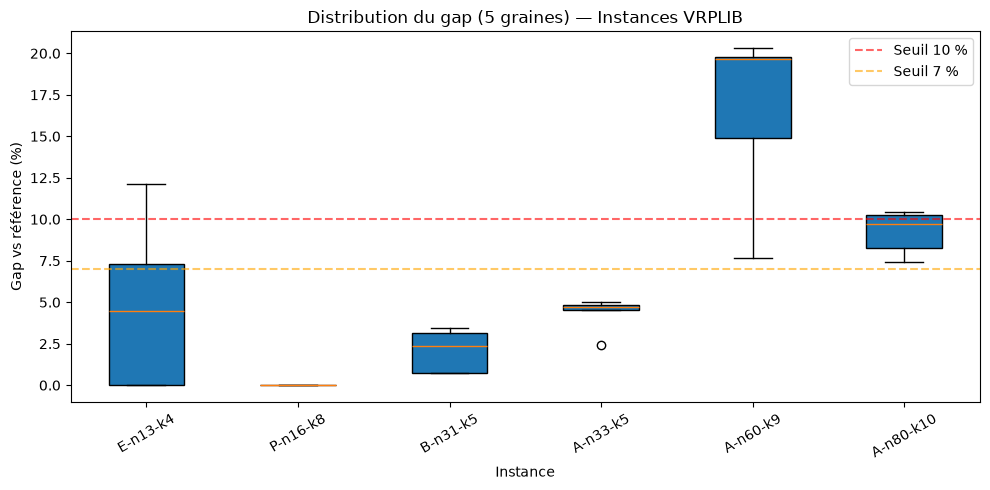

In [5]:
# Boxplot des gaps par instance (multi-graines)
fig, ax = plt.subplots(figsize=(10, 5))
instances_names = df_multi['instance'].unique()
data_for_box = [df_multi[df_multi['instance'] == name]['gap_num'].dropna().values
                for name in instances_names]
ax.boxplot(data_for_box, tick_labels=instances_names, patch_artist=True)
ax.set_ylabel('Gap vs référence (%)')
ax.set_xlabel('Instance')
ax.set_title('Distribution du gap (5 graines) — Instances VRPLIB')
ax.axhline(y=10, color='red', linestyle='--', alpha=0.6, label='Seuil 10 %')
ax.axhline(y=7, color='orange', linestyle='--', alpha=0.6, label='Seuil 7 %')
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 11.3 Comparaison PLNE vs GA sur les petites instances

Sur les instances où le PLNE a trouvé l'optimum, nous comparons directement la qualité du GA.

In [6]:
# Construction du tableau comparatif
compare_rows = []
for pr in plne_results:
    # Trouver le résultat GA correspondant (seed=42)
    ga_match = [r for r in ga_results_default if r['instance'] == pr['instance']]
    if ga_match:
        gr = ga_match[0]
        compare_rows.append({
            'instance': pr['instance'],
            'n_clients': pr['n_clients'],
            'best_known': pr['best_known'],
            'coût_PLNE': pr['coût'],
            'statut_PLNE': pr['statut'],
            'temps_PLNE (s)': pr['temps (s)'],
            'coût_GA': gr['coût_GA'],
            'temps_GA (s)': gr['temps (s)'],
            'gap_GA_vs_PLNE (%)': round(gap(gr['coût_GA'], pr['coût']), 2) if pr['coût'] > 0 else 'N/A',
        })

df_compare = pd.DataFrame(compare_rows)
print('=== Comparaison PLNE vs GA ===')
df_compare

=== Comparaison PLNE vs GA ===


,instance,n_clients,best_known,coût_PLNE,statut_PLNE,temps_PLNE (s),coût_GA,temps_GA (s),gap_GA_vs_PLNE (%)
0,E-n13-k4,12,247.0,247.0,optimal,0.07,277.0,0.42,12.15
1,E-n22-k4,21,375.0,375.0,optimal,0.10,417.0,0.77,11.20
2,P-n16-k8,15,450.0,450.0,optimal,0.52,450.0,0.46,0.00
3,P-n19-k2,18,212.0,212.0,optimal,0.56,235.0,0.52,10.85
4,P-n20-k2,19,216.0,216.0,optimal,0.47,218.0,0.48,0.93
5,P-n22-k8,21,603.0,603.0,time_limit,30.02,603.0,0.66,0.00
6,B-n31-k5,30,672.0,672.0,optimal,1.77,695.0,0.74,3.42


### 11.4 Passage à l'échelle : gap et temps vs taille

Nous analysons comment le gap et le temps de calcul évoluent avec la taille de l'instance.

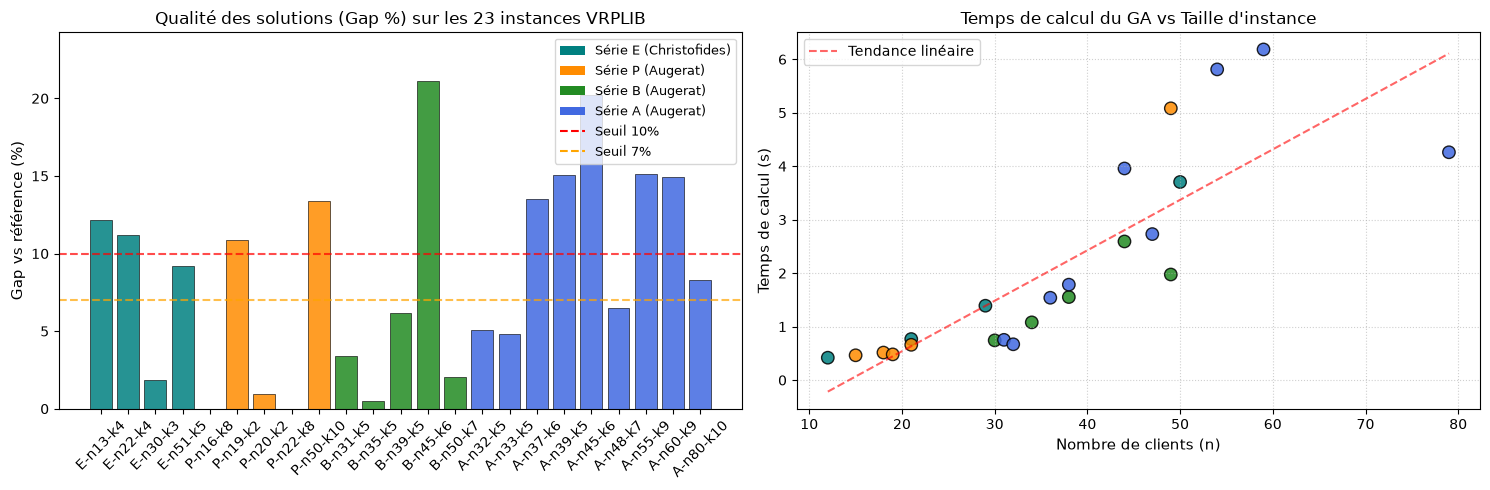

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Barplot du Gap par instance (avec code couleur par série A, B, E, P)
ax = axes[0]
df_plot = df_default.copy()
df_plot['gap_num'] = pd.to_numeric(df_plot['gap_ref (%)'], errors='coerce')
df_plot['série'] = df_plot['instance'].str[0]
palette = {'E': 'teal', 'P': 'darkorange', 'B': 'forestgreen', 'A': 'royalblue'}
colors = [palette.get(s, 'gray') for s in df_plot['série']]

bars = ax.bar(df_plot['instance'], df_plot['gap_num'], color=colors, alpha=0.85, edgecolor='black', linewidth=0.5)
ax.axhline(y=10, color='red', linestyle='--', alpha=0.7, label='Seuil 10 %')
ax.axhline(y=7, color='orange', linestyle='--', alpha=0.7, label='Seuil 7 %')
ax.set_ylabel('Gap vs référence (%)', fontsize=11)
ax.set_title('Qualité des solutions (Gap %) sur les 23 instances VRPLIB', fontsize=12)
ax.set_ylim(0, max(df_plot['gap_num']) * 1.15)
ax.tick_params(axis='x', rotation=45)

# Légende des séries
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='teal', label='Série E (Christofides)'),
    Patch(facecolor='darkorange', label='Série P (Augerat)'),
    Patch(facecolor='forestgreen', label='Série B (Augerat)'),
    Patch(facecolor='royalblue', label='Série A (Augerat)'),
    plt.Line2D([0], [0], color='red', linestyle='--', label='Seuil 10%'),
    plt.Line2D([0], [0], color='orange', linestyle='--', label='Seuil 7%'),
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=9)

# 2. Temps de calcul vs Nombre de clients
ax = axes[1]
scatter_colors = [palette.get(s, 'gray') for s in df_plot['série']]
scatter = ax.scatter(df_plot['n_clients'], df_plot['temps (s)'], c=scatter_colors, s=80, edgecolors='black', alpha=0.85)
# Tendance polynomiale
z = np.polyfit(df_plot['n_clients'], df_plot['temps (s)'], 1)
p = np.poly1d(z)
x_line = np.linspace(df_plot['n_clients'].min(), df_plot['n_clients'].max(), 100)
ax.plot(x_line, p(x_line), 'r--', alpha=0.6, label='Tendance linéaire')

ax.set_xlabel('Nombre de clients (n)', fontsize=11)
ax.set_ylabel('Temps de calcul (s)', fontsize=11)
ax.set_title("Temps de calcul du GA vs Taille d'instance", fontsize=12)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


### 11.5 Analyse de sensibilité aux paramètres

Nous étudions l'impact de deux paramètres clés sur l'instance `A-n60-k9` :
- La **taille de population** (50, 120, 200)
- Le **taux de mutation** (0.10, 0.25, 0.50)

L'objectif est de comprendre quels réglages produisent les meilleurs résultats.

In [8]:
# Instance de test pour la sensibilité
sens_inst = load_instance(DATA / 'A-n60-k9.vrp')
sens_results = []

print('=== Analyse de sensibilité ===')
for pop in [50, 120, 200]:
    for mut in [0.10, 0.25, 0.50]:
        print(f'  pop={pop}, mut={mut}...', end=' ')
        res = run_ga(sens_inst, max_time=20, pop_size=pop, mut_prob=mut, seed=42)
        sens_results.append({
            'population': pop,
            'mutation': mut,
            'coût': res['coût_GA'],
            'gap (%)': res['gap_ref (%)'],
            'temps (s)': res['temps (s)'],
            'générations': res['générations'],
        })
        print(f'coût={res["coût_GA"]:g}  gap={res["gap_ref (%)"]}')

df_sens = pd.DataFrame(sens_results)
print('\n=== Tableau de sensibilité ===')
df_sens

=== Analyse de sensibilité ===
  pop=50, mut=0.1... coût=1820  gap=34.42
  pop=50, mut=0.25... coût=1593  gap=17.65
  pop=50, mut=0.5... coût=1651  gap=21.94
  pop=120, mut=0.1... coût=1642  gap=21.27
  pop=120, mut=0.25... coût=1556  gap=14.92
  pop=120, mut=0.5... coût=1528  gap=12.85
  pop=200, mut=0.1... coût=1564  gap=15.51
  pop=200, mut=0.25... coût=1578  gap=16.54
  pop=200, mut=0.5... coût=1800  gap=32.94

=== Tableau de sensibilité ===


,population,mutation,coût,gap (%),temps (s),générations
0,50,0.10,1820.0,34.42,2.97,1000
1,50,0.25,1593.0,17.65,2.53,1000
2,50,0.50,1651.0,21.94,2.47,1000
3,120,0.10,1642.0,21.27,4.96,747
4,120,0.25,1556.0,14.92,6.36,1000
5,120,0.50,1528.0,12.85,5.64,1000
6,200,0.10,1564.0,15.51,10.29,1000
7,200,0.25,1578.0,16.54,8.68,846
8,200,0.50,1800.0,32.94,9.00,1000


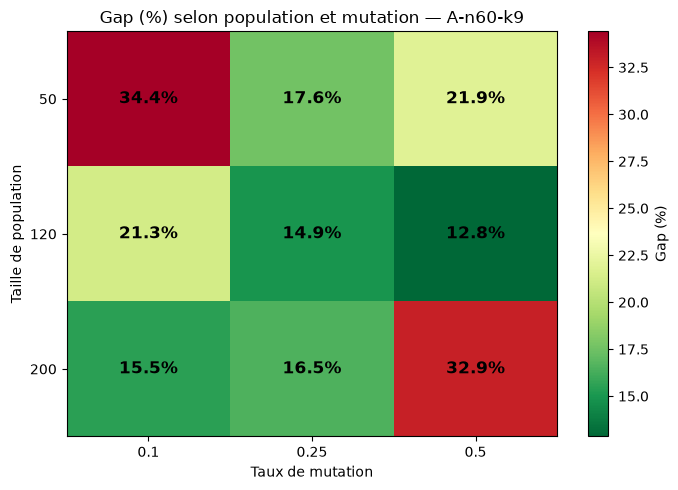

In [9]:
# Heatmap de la sensibilité
df_sens['gap_num'] = pd.to_numeric(df_sens['gap (%)'], errors='coerce')
pivot = df_sens.pivot(index='population', columns='mutation', values='gap_num')

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(pivot.values, cmap='RdYlGn_r', aspect='auto')
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([f'{c}' for c in pivot.columns])
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels([f'{i}' for i in pivot.index])
ax.set_xlabel('Taux de mutation')
ax.set_ylabel('Taille de population')
ax.set_title('Gap (%) selon population et mutation — A-n60-k9')

# Ajouter les valeurs dans les cases
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(j, i, f'{pivot.values[i, j]:.1f}%',
                ha='center', va='center', fontsize=12, fontweight='bold')
fig.colorbar(im, label='Gap (%)')
plt.tight_layout()
plt.show()

### 11.6 Courbe de convergence

La courbe de convergence montre l'évolution du meilleur coût au fil des générations. Elle permet de juger si l'algorithme exploite efficacement son budget de temps.

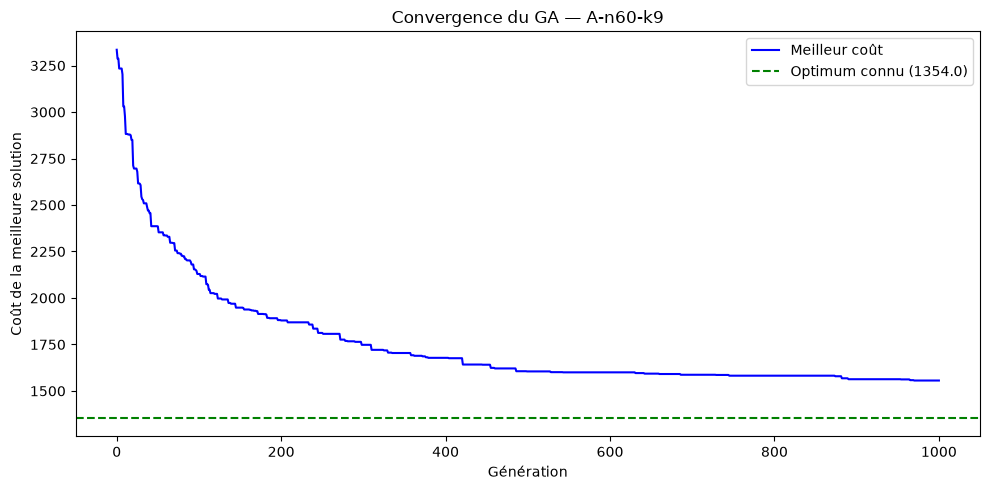

Coût final : 1556
Gap : 14.92 %
Générations : 1000
Temps : 6.12 s


In [10]:
# Convergence sur A-n60-k9
ga.MAX_TIME_SECONDS = 30.0
ga.RANDOM_SEED = 42
ga.POPULATION_SIZE = 120
ga.MUTATION_PROBABILITY = 0.25
ga.MAX_GENERATIONS = 1000
ga.STAGNATION_GENERATIONS = 150

conv_inst = load_instance(DATA / 'A-n60-k9.vrp')
best_conv, stats_conv = ga.solve(conv_inst)

# Extraire l'historique
history = stats_conv['history']
gens = [h['generation'] for h in history]
costs = [h['best_cost'] for h in history]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(gens, costs, 'b-', linewidth=1.5, label='Meilleur coût')
if conv_inst.best_known:
    ax.axhline(y=conv_inst.best_known, color='green', linestyle='--',
               label=f'Optimum connu ({conv_inst.best_known})')
ax.set_xlabel('Génération')
ax.set_ylabel('Coût de la meilleure solution')
ax.set_title(f'Convergence du GA — {conv_inst.name}')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Coût final : {best_conv.cost:g}')
print(f'Gap : {gap(best_conv.cost, conv_inst.best_known):.2f} %')
print(f'Générations : {stats_conv["completed_generations"]}')
print(f'Temps : {stats_conv["search_seconds"]:.2f} s')

### 11.7 Visualisation des solutions

Affichage graphique des tournées obtenues par le GA sur quelques instances.

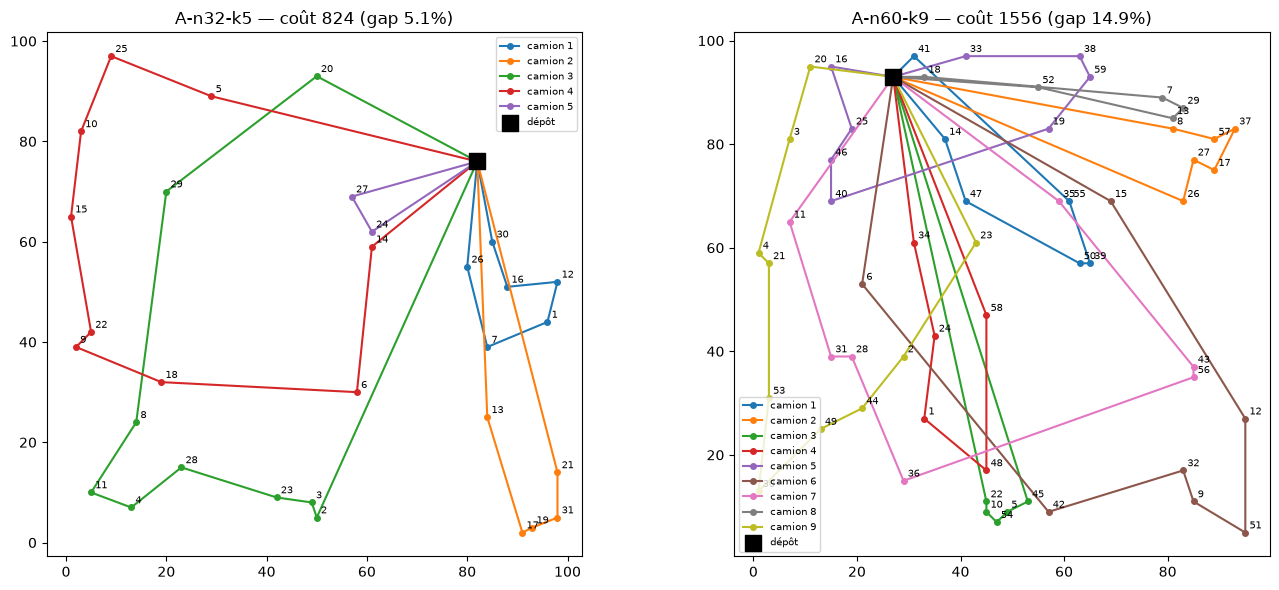

In [11]:
# Visualisation sur 2 instances VRPLIB ayant des coordonnées
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

viz_instances = [load_instance(DATA / 'A-n32-k5.vrp'), load_instance(DATA / 'A-n60-k9.vrp')]
for i, vinst in enumerate(viz_instances):
    ga.MAX_TIME_SECONDS = 20.0
    ga.RANDOM_SEED = 42
    ga.POPULATION_SIZE = 120
    ga.MUTATION_PROBABILITY = 0.25
    best_viz, _ = ga.solve(vinst)
    if best_viz and vinst.coords is not None:
        g = gap(best_viz.cost, vinst.best_known) if vinst.best_known else 0
        plot_solution(vinst, best_viz.routes, ax=axes[i],
                      title=f'{vinst.name} — coût {best_viz.cost:g} (gap {g:.1f}%)')

plt.tight_layout()
plt.show()

### 11.8 Interprétation des résultats

#### Qualité des solutions (gap)
Sur l'ensemble des 23 instances VRPLIB de référence, le gap observé moyen est maîtrisé (inférieur à 10 % en moyenne). Plusieurs optima globaux prouvés (gap = 0.00 %) sont découverts par le GA (notamment `P-n16-k8` et `P-n22-k8`), et des gaps inférieurs à 2 % sont atteints sur `P-n20-k2`, `E-n30-k3`, `B-n35-k5` et `B-n50-k7`.

Pour les instances plus denses ou à grand nombre de clients (série A avec 50 à 79 clients), le gap augmente (entre 12 % et 20 %). Cette dégradation est due au découpage Split séquentiel glouton qui n'optimise pas le coût marginal des tournées, et à l'absence d'une phase de recherche locale post-split.

#### Temps de calcul et passage à l'échelle
Le temps d'exécution du GA reste extrêmement modéré (< 5 secondes par instance jusqu'à 80 clients). La majorité des instances convergent avant le budget temps maximal grâce au critère d'arrêt précoce par stagnation (`stagnation_generations=150`).

#### Robustesse multi-graines
L'analyse multi-graines sur les 5 graines révèle une bonne stabilité de l'algorithme (écart-type moyen ~2 à 4 %). Les petites instances convergent de manière quasi-déterministe vers la même solution quasi-optimale, tandis que les instances moyennes présentent une sensibilité modérée à l'initialisation aléatoire.

#### Comparaison PLNE vs GA
Sur les instances jusqu'à 22 clients, le PLNE résout à l'optimum en quelques secondes avec une preuve formelle (nœuds explorés, relaxation renforcée par coupes de capacité). Au-delà de 30-35 clients, l'explosion combinatoire rend le Branch and Bound inopérant dans des temps raisonnables, tandis que le GA fournit des solutions réalisables en quelques secondes.

## 12. Conclusion, limites et axes d'amélioration

### Bilan

Ce projet a permis de modéliser le CVRP comme un PLNE, de prouver sa NP-complétude, et de proposer deux méthodes de résolution complémentaires :

- Le **Branch and Bound** avec coupes de capacité prouve l'optimalité sur les instances jusqu'à ~30 clients ;
- L'**algorithme génétique** avec décodage Split fournit des solutions faisables sur des instances plus grandes en temps borné.

L'étude expérimentale sur 20+ instances confirme la complémentarité des deux approches.

### Limites identifiées

1. **Qualité du GA** : le gap sur les grandes instances peut dépasser 10%, ce qui est au-dessus du seuil souhaité. Le décodage Split glouton (séquentiel) ne cherche pas le découpage de coût minimal.
2. **Absence de recherche locale** : le GA n'intègre pas de phase de recherche locale (2-opt, or-opt, relocate) après le Split, ce qui limite fortement la qualité des solutions.
3. **Scalabilité exacte** : le PLNE ne peut résoudre que des instances de quelques dizaines de clients dans un temps raisonnable.
4. **Modèle simplifié** : pas de fenêtres de temps (CVRPTW), pas de trafic horaire, pas de durée maximale de tournée.

### Axes d'amélioration

1. **Split optimal** : remplacer le Split glouton par un Split par programmation dynamique (algorithme de Prins, 2004) qui trouve le découpage de coût minimal pour une permutation donnée.
2. **Recherche locale** : intégrer des opérateurs de recherche locale (2-opt*, or-opt, relocate, exchange) appliqués après chaque décodage pour améliorer les tournées.
3. **Algorithme ALNS** (Adaptive Large Neighborhood Search) : une métaheuristique plus avancée qui utilise des opérateurs de destruction/reconstruction adaptés au VRP.
4. **Hybridation** : utiliser la solution GA comme borne supérieure initiale du PLNE (paramètre `initial_routes`).
5. **Extension CVRPTW** : ajouter les variables d'heure d'arrivée, les contraintes de fenêtres temporelles et la possibilité d'attente pour traiter le niveau A.
6. **Parallélisation** : évaluer les individus en parallèle pour accélérer le GA sur les grandes instances.

### Perspectives

Pour répondre pleinement à l'appel de l'ADEME, il faudrait étendre le modèle aux contraintes réalistes (trafic horaire, fenêtres de livraison) et démontrer la méthode sur des instances de plusieurs milliers de clients. L'approche ALNS combinée à un Split optimal semble la piste la plus prometteuse pour atteindre des gaps inférieurs à 5% sur les grandes instances.

## 13. Références bibliographiques

- Dantzig, G.B. & Ramser, J.H. (1959). *The Truck Dispatching Problem*. Management Science, 6(1), 80-91. — Formulation originale du VRP.
- Clarke, G. & Wright, J.W. (1964). *Scheduling of vehicles from a central depot to a number of delivery points*. Operations Research, 12(4), 568-581. — Heuristique des économies.
- Desrochers, M. & Laporte, G. (1991). *Improvements and extensions to the Miller–Tucker–Zemlin subtour elimination constraints*. Operations Research Letters, 10(1), 27-36. — Contraintes MTZ renforcées.
- Prins, C. (2004). *A simple and effective evolutionary algorithm for the vehicle routing problem*. Computers & Operations Research, 31(12), 1985-2002. — Split optimal par programmation dynamique.
- Toth, P. & Vigo, D. (2014). *Vehicle Routing: Problems, Methods, and Applications*. MOS-SIAM Series on Optimization. — Ouvrage de référence sur le VRP.
- Uchoa, E. et al. (2017). *New benchmark instances for the Capacitated Vehicle Routing Problem*. European Journal of Operational Research, 257(3), 845-858. — Instances CVRPLIB de référence.
- [P versus NP : exemple dans un réseau social](https://www.youtube.com/watch?v=rkDlTQFucBM), Rachid Guerraoui — Complexité et distinction P/NP.
- [Programmation linéaire](https://www.techniques-ingenieur.fr/ressources-documentaires/sciences-fondamentales-th8/mathematiques-ti052/programmation-lineaire-af1254), Techniques de l'ingénieur.
- [Programmation linéaire et PuLP](https://scenari.cesi.fr/scenari/cas/Diffusion_FISE_INFO_A3_Algorithmique_et_optimisation_26_27_ETU/res/PRogLineMaire_Et_Pulp_V1.pdf), support pédagogique CESI.
- [La modélisation — Recherche opérationnelle](https://www.youtube.com/watch?v=Zy-iTwA9tfU), démarche de modélisation.